In [1]:
import numpy as np
import tifffile
import matplotlib.pyplot as plt
import cv2

from scipy.ndimage import zoom
from scipy.ndimage import correlate

In [2]:
'''loading data'''
original_msi = np.load("D:/geoinformatics/MajorProject/main/npyfiles/rgb_npy/WG_RGB_BLOCK_0_1.npy")
original_msi = np.transpose(original_msi, (1, 2, 0))
original_pan = np.load("D:/geoinformatics/MajorProject/main/npyfiles/pan_npy/WG_PAN_BLOCK_0_1.npy")
original_pan = np.transpose(original_pan, (1, 2, 0))

In [3]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & uint16
(1024, 1024, 1) & uint16


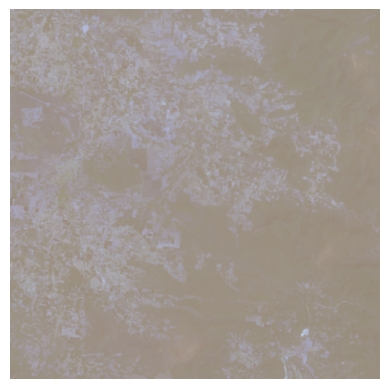

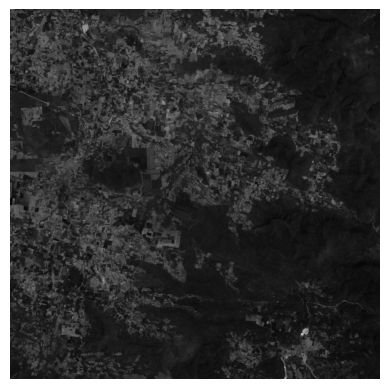

In [4]:
# Extract the RGB channels
rgb_image = original_msi[..., :3]

# Since the image is in uint16 format, we need to normalize it for display
# Normalize to range [0, 1] for matplotlib
rgb_image = rgb_image.astype(np.float32) / np.max(rgb_image)

# Display the RGB image
plt.imshow(rgb_image)
plt.axis('off')  # Hide the axes
plt.show()

plt.axis("off")
plt.imshow(original_pan, cmap= 'gray')

In [5]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & uint16
(1024, 1024, 1) & uint16


In [6]:
gt = np.uint8(np.resize(original_msi, (1024, 1024, 4)))

In [7]:
print(gt.shape , "&", gt.dtype)

(1024, 1024, 4) & uint8


In [8]:
def resize_window(w, target_shape):
    """
    Resize the window function to match the target shape.
    """
    factors = (target_shape[0] / w.shape[0], target_shape[1] / w.shape[1])
    resized_w = zoom(w, factors, mode='constant')
    return resized_w

In [9]:
def fir_filter_wind(Hd, w):
    """
    compute fir (finite impulse response) filter with window method
    Hd: desired freqeuncy response (2D)
    w: window (2D)
    """
    hd = np.rot90(np.fft.fftshift(np.rot90(Hd, 2)), 2)
    h = np.fft.fftshift(np.fft.ifft2(hd))
    h = np.rot90(h, 2)

    if h.shape != w.shape:
        w = resize_window(w, h.shape)
        print(f"Shape of w after resizing: {w.shape}")
    h = h * w
    h = h / np.sum(h)
    return h

In [10]:
def gaussian2d(N, std):
    
    t=np.arange(-(N-1)/2,(N+2)/2)
    t1,t2=np.meshgrid(t,t)
    std=np.double(std)
    w = np.exp(-0.5*(t1/std)**2)*np.exp(-0.5*(t2/std)**2) 
    return w

In [11]:
def kaiser2d(N, beta):
    
    t=np.arange(-(N-1)/2,(N+1)/2)/np.double(N-1)
    t1,t2=np.meshgrid(t,t)
    t12=np.sqrt(t1*t1+t2*t2)
    w1=np.kaiser(N,beta)
    w=np.interp(t12,t,w1)
    w[t12>t[-1]]=0
    w[t12<t[0]]=0
    
    return w

In [12]:
def GNyq2win(GNyq, scale=2, N=41):
    """Generate a 2D convolutional window from a given GNyq
    GNyq: Nyquist frequency
    scale: spatial size of PAN / spatial size of MS
    """
    #fir filter with window method
    fcut = 1 / scale
    alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyq)))
    H = gaussian2d(N, alpha)
    Hd = H / np.max(H)
    w = kaiser2d(N, 0.5)
    h = fir_filter_wind(Hd, w)
    return np.real(h)

In [13]:
def mtf_resize(img, satellite='landsat8', scale=2):
    # satellite GNyq
    scale = int(scale)
    if satellite == 'landsat8':
        GNyq = [0.29, 0.26, 0.26,0.25]  # Band Order: B,G,R,NIR
        GNyqPan = 0.23
    else:
        raise NotImplementedError('satellite: landsat 8')
    # lowpass
    img_ = img.squeeze()
    img_ = img_.astype(np.float64)
    if img_.ndim == 2:  # Pan
        H, W = img_.shape
        lowpass = GNyq2win(GNyqPan, scale = 2, N=41)
    elif img_.ndim == 3:  # MS
        H, W, _ = img.shape
        lowpass = [GNyq2win(gnyq, scale = 2, N=41) for gnyq in GNyq]
        lowpass = np.stack(lowpass, axis=-1)
    img_ = correlate(img_, lowpass, mode='nearest')
    # downsampling
    output_size = (H // scale, W // scale)
    img_ = cv2.resize(img_, dsize=output_size, interpolation=cv2.INTER_NEAREST)
    return img_

In [14]:
def sam(img1, img2):
    """SAM for 3D image, shape (H, W, C); uint or float[0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    
    if img1.ndim != 3 or img1.shape[2] <= 1:
        raise ValueError('Images must be 3D with more than 1 channel.')

    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)

    inner_product = np.sum(img1_ * img2_, axis=2)
    img1_spectral_norm = np.sqrt(np.sum(img1_**2, axis=2))
    img2_spectral_norm = np.sqrt(np.sum(img2_**2, axis=2))

    # Avoid division by zero
    norm_product = img1_spectral_norm * img2_spectral_norm
    norm_product = np.where(norm_product == 0, np.finfo(np.float64).eps, norm_product)

    cos_theta = np.clip(inner_product / norm_product, -1.0, 1.0)
    
    return np.mean(np.arccos(cos_theta))

In [15]:
def psnr(img1, img2, dynamic_range=255):
    """PSNR metric, img uint8 if 225; uint16 if 2047"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    mse = np.mean((img1_ - img2_)**2)
    if mse <= 1e-10:
        return np.inf
    return 20 * np.log10(dynamic_range / (np.sqrt(mse) + np.finfo(np.float64).eps))

In [16]:
def scc(img1, img2):
    """SCC for 2D (H, W)or 3D (H, W, C) image; uint or float[0, 1]"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    if img1_.ndim == 2:
        return np.corrcoef(img1_.reshape(1, -1), img2_.rehshape(1, -1))[0, 1]
    elif img1_.ndim == 3:
        #print(img1_[..., i].reshape[1, -1].shape)
        #test = np.corrcoef(img1_[..., i].reshape[1, -1], img2_[..., i].rehshape(1, -1))
        #print(type(test))
        ccs = [np.corrcoef(img1_[..., i].reshape(1, -1), img2_[..., i].reshape(1, -1))[0, 1]
               for i in range(img1_.shape[2])]
        return np.mean(ccs)
    else:
        raise ValueError('Wrong input image dimensions.')

In [17]:
def _qindex(img1, img2, block_size=8):
    """Q-index for 2D (one-band) image, shape (H, W); uint or float [0, 1]"""
    assert block_size > 1, 'block_size shold be greater than 1!'
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    window = np.ones((block_size, block_size)) / (block_size**2)
    # window_size = block_size**2
    # filter, valid
    pad_topleft = int(np.floor(block_size/2))
    pad_bottomright = block_size - 1 - pad_topleft
    mu1 = cv2.filter2D(img1_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu2 = cv2.filter2D(img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu2_sq
#    print(mu1_mu2.shape)
    #print(sigma2_sq.shape)
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_mu2

    # all = 1, include the case of simga == mu == 0
    qindex_map = np.ones(sigma12.shape)
    # sigma == 0 and mu != 0
    
#    print(np.min(sigma1_sq + sigma2_sq), np.min(mu1_sq + mu2_sq))
    
    idx = ((sigma1_sq + sigma2_sq) < 1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] = 2 * mu1_mu2[idx] / (mu1_sq + mu2_sq)[idx]
    # sigma !=0 and mu == 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) < 1e-8)
    qindex_map[idx] = 2 * sigma12[idx] / (sigma1_sq + sigma2_sq)[idx]
    # sigma != 0 and mu != 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] =((2 * mu1_mu2[idx]) * (2 * sigma12[idx])) / (
        (mu1_sq + mu2_sq)[idx] * (sigma1_sq + sigma2_sq)[idx])
    
    return np.mean(qindex_map)


def qindex(img1, img2, block_size=8):
    """Q-index for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _qindex(img1, img2, block_size)
    elif img1.ndim == 3:
        qindexs = [_qindex(img1[..., i], img2[..., i], block_size) for i in range(img1.shape[2])]
        return np.array(qindexs).mean()
    else:
        raise ValueError('Wrong input image dimensions.')

In [18]:
def _ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (one-band) image, shape (H, W); uint8 if 225; uint16 if 2047"""
    C1 = (0.01 * dynamic_range)**2
    C2 = (0.03 * dynamic_range)**2
    
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    kernel = cv2.getGaussianKernel(11, 1.5)  # kernel size 11
    window = np.outer(kernel, kernel.transpose())
    
    mu1 = cv2.filter2D(img1_, -1, window)[5:-5, 5:-5]  # valid
    mu2 = cv2.filter2D(img2_, -1, window)[5:-5, 5:-5]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[5:-5, 5:-5] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[5:-5, 5:-5] - mu2_sq
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[5:-5, 5:-5] - mu1_mu2
    
    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / (
        (mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim_map.mean()



def ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (H, W) or 3D (H, W, C) image; uint8 if 225; uint16 if 2047"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _ssim(img1, img2, dynamic_range)
    elif img1.ndim == 3:
        ssims = [_ssim(img1[..., i], img2[..., i], dynamic_range) for i in range(img1.shape[2])]
        return np.array(ssims).mean()
    else:
        raise ValueError('Wrong input image dimensions.')


In [19]:
def ergas(img_fake, img_real, scale=4):
    """ERGAS for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1].
    scale = spatial resolution of PAN / spatial resolution of MUL, default 4."""
    if not img_fake.shape == img_real.shape:
        raise ValueError('Input images must have the same dimensions.')
    img_fake_ = img_fake.astype(np.float64)
    img_real_ = img_real.astype(np.float64)
    if img_fake_.ndim == 2:
        mean_real = img_real_.mean()
        mse = np.mean((img_fake_ - img_real_)**2)
        return 100 / scale * np.sqrt(mse / (mean_real**2 + np.finfo(np.float64).eps))
    elif img_fake_.ndim == 3:
        means_real = img_real_.reshape(-1, img_real_.shape[2]).mean(axis=0)
        mses = ((img_fake_ - img_real_)**2).reshape(-1, img_fake_.shape[2]).mean(axis=0)
        return 100 / scale * np.sqrt((mses / (means_real**2 + np.finfo(np.float64).eps)).mean())
    else:
        raise ValueError('Wrong input image dimensions.')

In [20]:
def D_lambda(img_fake, img_lm, block_size=32, p=1):
    """Spectral distortion
    img_fake, generated HRMS
    img_lm, LRMS"""
    assert img_fake.ndim == img_lm.ndim == 3, 'Images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # D_lambda
    Q_fake = []
    Q_lm = []
    for i in range(C_f):
        for j in range(i+1, C_f):
            # for fake
            band1 = img_fake[..., i]
            band2 = img_fake[..., j]
            Q_fake.append(_qindex(band1, band2, block_size=block_size))
            # for real
            band1 = img_lm[..., i]
            band2 = img_lm[..., j]
            Q_lm.append(_qindex(band1, band2, block_size=block_size))
    Q_fake = np.array(Q_fake)
    Q_lm = np.array(Q_lm)
    D_lambda_index = (np.abs(Q_fake - Q_lm) ** p).mean()
    return D_lambda_index ** (1/p)

In [21]:
def D_s(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, q=1):
    """Spatial distortion
    img_fake, generated HRMS
    img_lm, LRMS
    pan, HRPan"""
    # fake and lm
    assert img_fake.ndim == img_lm.ndim == 3, 'MS images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    print(f"H_f: {H_f}, W_f: {W_f}, H_r: {H_r}, W_r: {W_r}, scale: {scale}")
    assert H_f // H_r == W_f // W_r == scale, 'Spatial resolution should be compatible with scale'
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # fake and pan
    assert pan.ndim == 3, 'Panchromatic image must be 3D!'
    H_p, W_p, C_p = pan.shape
    assert C_p == 1, 'size of 3rd dim of Panchromatic image must be 1'
    assert H_f == H_p and W_f == W_p, "Pan's and fake's spatial resolution should be the same"
    # get LRPan, 2D
    pan_lr = mtf_resize(pan, satellite=satellite, scale=scale)
    #print(pan_lr.shape)
    # D_s
    Q_hr = []
    Q_lr = []
    for i in range(C_f):
        # for HR fake
        band1 = img_fake[..., i]
        band2 = pan[..., 0] # the input PAN is 3D with size=1 along 3rd dim
        #print(band1.shape)
        #print(band2.shape)
        Q_hr.append(_qindex(band1, band2, block_size=block_size))
        band1 = img_lm[..., i]
        band2 = pan_lr  # this is 2D
        #print(band1.shape)
        #print(band2.shape)
        Q_lr.append(_qindex(band1, band2, block_size=block_size))
    Q_hr = np.array(Q_hr)
    Q_lr = np.array(Q_lr)
    D_s_index = (np.abs(Q_hr - Q_lr) ** q).mean()
    return D_s_index ** (1/q)

In [22]:
def qnr(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, p=1, q=1, alpha=1, beta=1):
    """QNR - No reference IQA"""
    D_lambda_idx = D_lambda(img_fake, img_lm, block_size, p)
    D_s_idx = D_s(img_fake, img_lm, pan, satellite, scale, block_size, q)
    QNR_idx = (1 - D_lambda_idx) ** alpha * (1 - D_s_idx) ** beta
    return QNR_idx

In [23]:
def ref_evaluate(pred, gt):
    #reference metrics
    c_psnr = psnr(pred, gt)
    c_ssim = ssim(pred, gt)
    c_sam = sam(pred, gt)
    c_ergas = ergas(pred, gt)
    c_scc = scc(pred, gt)
    c_q = qindex(pred, gt)

    return [c_psnr, c_ssim, c_sam, c_ergas, c_scc, c_q]

In [24]:
def no_ref_evaluate(pred, pan, hs):
    #no reference metrics
    c_D_lambda = D_lambda(pred, hs)
    c_D_s = D_s(pred, hs, pan)
    c_qnr = qnr(pred, hs, pan)
    
    return [c_D_lambda, c_D_s, c_qnr]

In [25]:
'''evaluating all methods'''
ref_results={}
ref_results.update({'metrics: ':'  PSNR,     SSIM,   SAM,    ERGAS,  SCC,    Q'})
no_ref_results={}
no_ref_results.update({'metrics: ':'  D_lamda, D_s,    QNR'})

In [26]:
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)

pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8


In [27]:
bicubic_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/Bicubic/georef/georef_Bicubic_0_1.tif")
print("fused:", bicubic_fused_image.shape, "&", bicubic_fused_image.dtype)
temp_ref_results = ref_evaluate(bicubic_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(bicubic_fused_image, pann, msss)
ref_results.update({'Bicubic    ':temp_ref_results})
no_ref_results.update({'Bicubic    ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [28]:
Brovey_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/Brovey/georef/georef_Brovey_0_1.tif")
print("fused:", Brovey_fused_image.shape, "&", Brovey_fused_image.dtype)
temp_ref_results = ref_evaluate(Brovey_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(Brovey_fused_image, pann, msss)
ref_results.update({'Brovey     ':temp_ref_results})
no_ref_results.update({'Brovey     ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [29]:
PCA_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/PCA/georef/georef_PCA_0_1.tif")
print("fused:", PCA_fused_image.shape, "&", PCA_fused_image.dtype)
temp_ref_results = ref_evaluate(PCA_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(PCA_fused_image, pann, msss)
ref_results.update({'PCA        ':temp_ref_results})
no_ref_results.update({'PCA        ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [30]:
IHS_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/IHS/georef/georef_IHS_0_1.tif")
print("fused:", IHS_fused_image.shape, "&", IHS_fused_image.dtype)
temp_ref_results = ref_evaluate(IHS_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(IHS_fused_image, pann, msss)
ref_results.update({'IHS        ':temp_ref_results})
no_ref_results.update({'IHS        ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [31]:
SFIM_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/SFIM/georef/georef_SFIM_0_1.tif")
print("fused:", SFIM_fused_image.shape, "&", SFIM_fused_image.dtype)
temp_ref_results = ref_evaluate(SFIM_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(SFIM_fused_image, pann, msss)
ref_results.update({'SFIM       ':temp_ref_results})
no_ref_results.update({'SFIM       ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [32]:
GS_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/GS/georef/georef_GS_0_1.tif")
print("fused:", GS_fused_image.shape, "&", GS_fused_image.dtype)
temp_ref_results = ref_evaluate(GS_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(GS_fused_image, pann, msss)
ref_results.update({'GS         ':temp_ref_results})
no_ref_results.update({'GS         ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [33]:
Wavelet_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/Wavelet/georef/georef_Wavelet_0_1.tif")
print("fused:", Wavelet_fused_image.shape, "&", Wavelet_fused_image.dtype)
temp_ref_results = ref_evaluate(Wavelet_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(Wavelet_fused_image, pann, msss)
ref_results.update({'Wavelet    ':temp_ref_results})
no_ref_results.update({'Wavelet    ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [34]:
MTF_GLP_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/MTF_GLP/georef/georef_MTF_GLP_0_1.tif")
print("fused:", MTF_GLP_fused_image.shape, "&", MTF_GLP_fused_image.dtype)
temp_ref_results = ref_evaluate(MTF_GLP_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(MTF_GLP_fused_image, pann, msss)
ref_results.update({'MTF_GLP    ':temp_ref_results})
no_ref_results.update({'MTF_GLP    ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [35]:
MTF_GLP_HPM_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/MTF_GLP_HPM/georef/georef_MTF_GLP_HPM_0_1.tif")
print("fused:", MTF_GLP_HPM_fused_image.shape, "&", MTF_GLP_HPM_fused_image.dtype)
temp_ref_results = ref_evaluate(MTF_GLP_HPM_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(MTF_GLP_HPM_fused_image, pann, msss)
ref_results.update({'MTF_GLP_HPM    ':temp_ref_results})
no_ref_results.update({'MTF_GLP_HPM    ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [36]:
GSA_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/GSA/georef/georef_GSA_0_1.tif")
print("fused:", GSA_fused_image.shape, "&", GSA_fused_image.dtype)
temp_ref_results = ref_evaluate(GSA_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(GSA_fused_image, pann, msss)
ref_results.update({'GSA        ':temp_ref_results})
no_ref_results.update({'GSA        ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [37]:
CNMF_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/CNMF/georef/georef_CNMF_0_1.tif")
print("fused:", CNMF_fused_image.shape, "&", CNMF_fused_image.dtype)
temp_ref_results = ref_evaluate(CNMF_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(CNMF_fused_image, pann, msss)
ref_results.update({'CNMF       ':temp_ref_results})
no_ref_results.update({'CNMF       ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [38]:
GFPCA_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/GFPCA/georef/georef_GFPCA_0_1.tif")
print("fused:", GFPCA_fused_image.shape, "&", GFPCA_fused_image.dtype)
temp_ref_results = ref_evaluate(GFPCA_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(GFPCA_fused_image, pann, msss)
ref_results.update({'GFPCA      ':temp_ref_results})
no_ref_results.update({'GFPCA      ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [39]:
PanNet_fused_image = tifffile.imread("D:/geoinformatics/MajorProject/main/output_tif/bymethods/PanNet/georef/georef_PanNet_0_1.tif")
print("fused:", PanNet_fused_image.shape, "&", PanNet_fused_image.dtype)
temp_ref_results = ref_evaluate(PanNet_fused_image, gt)
temp_no_ref_results = no_ref_evaluate(PanNet_fused_image, pann, msss)
ref_results.update({'PanNet     ':temp_ref_results})
no_ref_results.update({'PanNet     ':temp_no_ref_results})

fused: (1024, 1024, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [40]:
''''print result'''
print('################## reference comparision #######################')
for index, i in enumerate(ref_results):
    if index == 0:
        print(i, ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in ref_results[i]])

print('################## reference comparision #######################')
      
      
print('################## no reference comparision ####################')
for index, i in enumerate(no_ref_results):
    if index == 0:
        print(i, no_ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in no_ref_results[i]])

print('################## no reference comparision ####################')

################## reference comparision #######################
metrics:    PSNR,     SSIM,   SAM,    ERGAS,  SCC,    Q
Bicubic     [7.5821, 0.0082, 0.687, 21.041, -0.0007, -0.0002]
Brovey      [7.568, 0.0082, 0.6867, 21.0747, -0.0004, -0.0001]
PCA         [8.0141, 0.0095, 0.4864, 20.0002, -0.0006, -0.0002]
IHS         [7.5841, 0.0082, 0.6856, 21.0361, -0.0005, -0.0002]
SFIM        [7.5608, 0.0082, 0.69, 21.0927, -0.0005, -0.0002]
GS          [7.5801, 0.0082, 0.687, 21.0459, -0.0005, -0.0002]
Wavelet     [7.572, 0.0082, 0.6875, 21.0652, -0.0005, -0.0002]
MTF_GLP     [7.4664, 0.0077, 0.708, 21.3236, -0.0005, -0.0002]
MTF_GLP_HPM     [7.5038, 0.0078, 0.6999, 21.2318, -0.0005, -0.0003]
GSA         [7.5444, 0.0081, 0.6948, 21.1328, -0.0007, -0.0002]
CNMF        [7.5853, 0.0082, 0.6851, 21.0331, -0.0007, -0.0002]
GFPCA       [7.6258, 0.0085, 0.68, 20.9352, -0.0005, -0.0001]
PanNet      [7.5482, 0.008, 0.6913, 21.1231, -0.0008, -0.0003]
################## reference comparision #############